# Deep RNN

In [2]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

In [3]:
import os, urllib.request

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/imdb.npz"
path = "imdb.npz"
if not os.path.exists(path):
    urllib.request.urlretrieve(url, path)

def load_imdb(path, start_char=1, index_from=3):
    with np.load(path, allow_pickle=True) as f:
        x_train, y_train = f["x_train"], f["y_train"]
        x_test, y_test = f["x_test"], f["y_test"]
    add = lambda xs: [[start_char] + [w + index_from for w in x] for x in xs]
    return (add(x_train), y_train), (add(x_test), y_test)

(X_train, y_train), (X_test, y_test) = load_imdb(path)

In [4]:
def pad_sequences(seqs, maxlen):
    out = np.zeros((len(seqs), maxlen), dtype=np.int64)
    for i, s in enumerate(seqs):
        s = s[-maxlen:]  # Keeps the last `maxlen` tokens (pre-truncating)
        out[i, maxlen - len(s) :] = s  # Pads with 0s at the beginning (pre-padding)
    return out


def load_imdb(path, start_char=1, index_from=3):
    with np.load(path, allow_pickle=True) as f:
        x_train, y_train = f["x_train"], f["y_train"]
        x_test, y_test = f["x_test"], f["y_test"]
    add = lambda xs: [[start_char] + [w + index_from for w in x] for x in xs]
    return (add(x_train), y_train), (add(x_test), y_test)


# 1. Load the raw variable-length sequences and labels
(X_train, y_train), (X_test, y_test) = load_imdb(path)

# 2. Pad X_train and X_test to a uniform length
max_len = 250  # Set your desired sequence length
X_train = pad_sequences(X_train, max_len)
X_test = pad_sequences(X_test, max_len)

print("X_train shape:", X_train.shape, "y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape, "y_test shape:", y_test.shape)


X_train shape: (25000, 250) y_train shape: (25000,)
X_test shape: (25000, 250) y_test shape: (25000,)


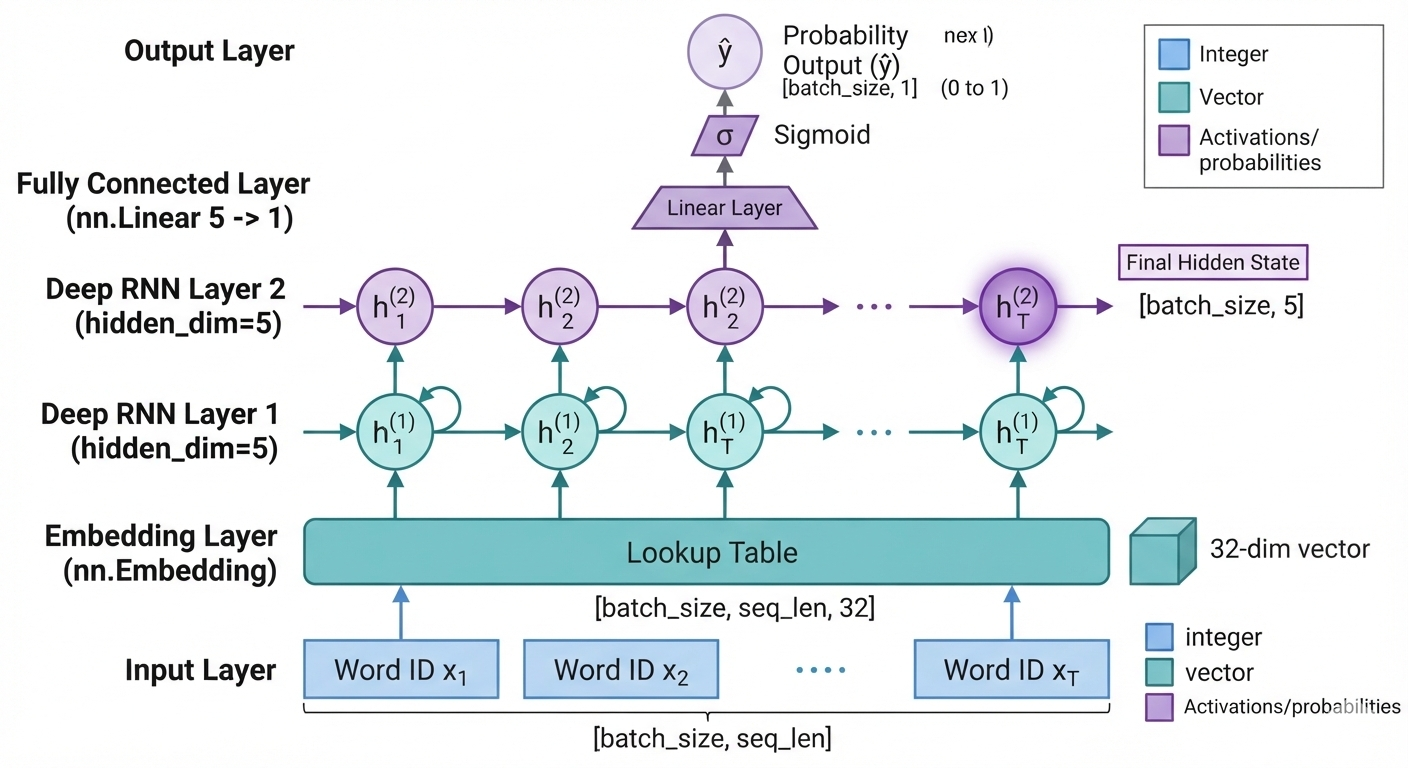

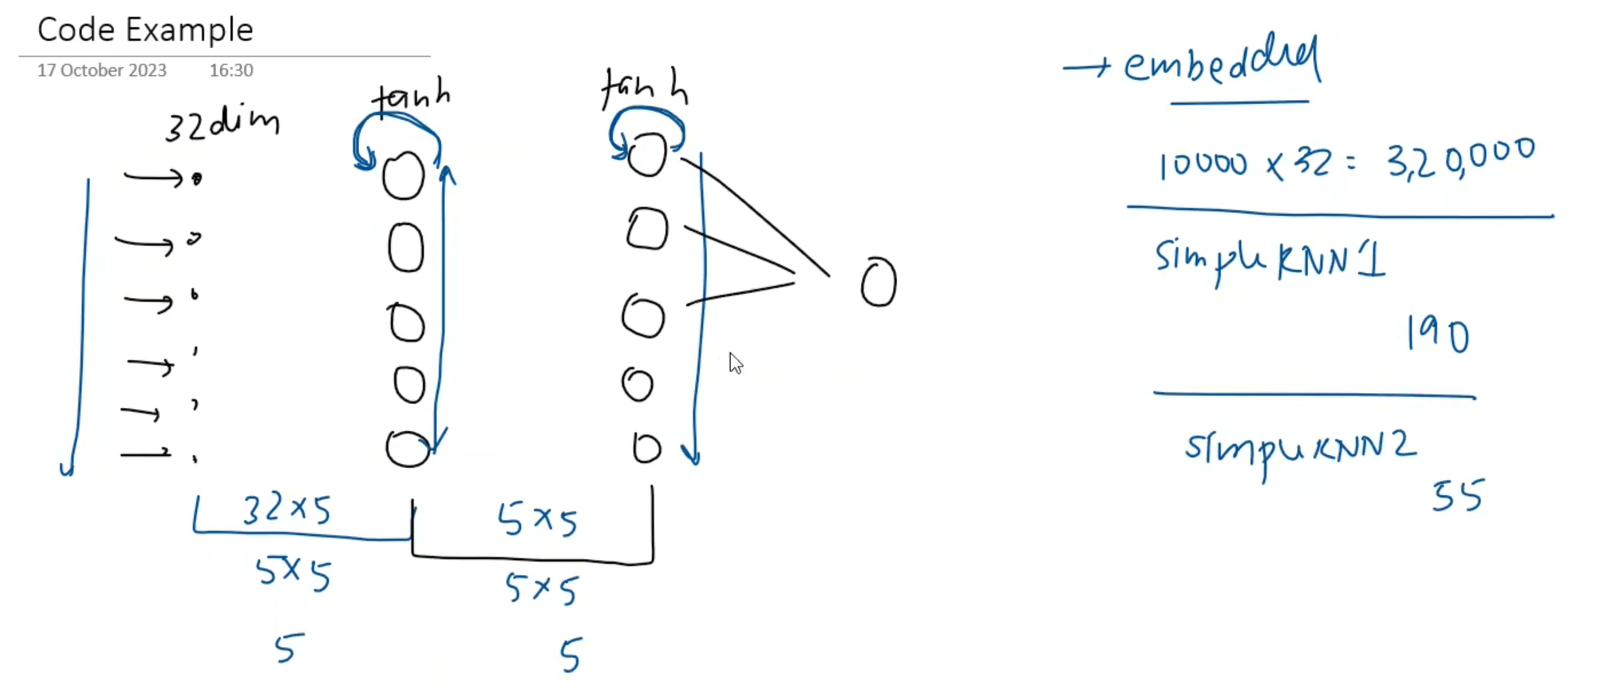

In [6]:
# define deep rnn model

class DeepRNN(nn.Module):
    def __init__(self, vocab_size=10000, embed_dim=32, hidden_dim=5):
        super(DeepRNN, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        # A 2-layer RNN to achieve deep RNN architecture
        self.rnn = nn.RNN(input_size=embed_dim, hidden_size=hidden_dim, num_layers=2, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        # x shape: [batch_size, seq_len]
        out = self.embedding(x)          # shape: [batch_size, seq_len, embed_dim]
        out, h_n = self.rnn(out)         # out shape: [batch_size, seq_len, hidden_dim]
        out = out[:, -1, :]              # take the last time step: [batch_size, hidden_dim]
        out = self.fc(out)               # shape: [batch_size, 1]
        return self.sigmoid(out)         # shape: [batch_size, 1]

model = DeepRNN()

In [14]:
!pip install -q torchinfo

import torch
from torchinfo import summary

# Display the model summary with an expected input size (e.g., batch_size=2, sequence_length=250)
summary(model)

Layer (type:depth-idx)                   Param #
DeepRNN                                  --
├─Embedding: 1-1                         320,000
├─RNN: 1-2                               255
├─Linear: 1-3                            6
├─Sigmoid: 1-4                           --
Total params: 320,261
Trainable params: 320,261
Non-trainable params: 0

In [15]:
X_t = torch.from_numpy(X_train).long()
y_t = torch.from_numpy(y_train).long()

from torch.utils.data import TensorDataset, DataLoader

dataset = TensorDataset(X_t, y_t)
loader = DataLoader(dataset, batch_size=32, shuffle=True)

In [ ]:
# Calculate the safe vocabulary size based on the dataset
max_vocab_index = int(max(X_train.max(), X_test.max()))
num_embeddings = max_vocab_index + 1
print(f"Detected maximum vocabulary index: {max_vocab_index}. Setting embedding vocab size to {num_embeddings}.")

# Re-initialize the model with the correct vocabulary size
model = DeepRNN(vocab_size=num_embeddings, embed_dim=32, hidden_dim=5)

# For binary classification with a final sigmoid output, we use Binary Cross Entropy Loss
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 3
print("=" * 50)

for epoch in range(1, epochs + 1):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        optimizer.zero_grad()
        probs = model(xb)             # Forward pass gives sigmoid probabilities of shape [batch_size, 1]
        probs = probs.squeeze(-1)     # Squeeze to shape [batch_size]

        loss = criterion(probs, yb.float())
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * xb.size(0)

        # Predict class 1 if probability >= 0.5, else class 0
        preds = (probs >= 0.5).long()
        correct += (preds == yb).sum().item()
        n += xb.size(0)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Epoch {epoch:3d}/{epochs} - Loss: {total_loss / n:.4f} - Accuracy: {correct / n:.4f}")

Detected maximum vocabulary index: 88586. Setting embedding vocab size to 88587.
Epoch   1/3 - Loss: 0.6895 - Accuracy: 0.5359
